# Will this online shopping session end with a purchase?

**ML Zoomcamp 2026 · midterm project**

An online shop wants to know, from the way a visitor browses, how likely the session is to
end with a purchase. With that probability the shop can react while the visitor is still on
the site (for example with an offer or a prompt for assistance) and can rank sessions for
follow-up. This is a **binary classification** problem; the full problem description is in
the [README](README.md).

**Data.** [Online Shoppers Purchasing Intention](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset)
from the UCI Machine Learning Repository (Sakar & Kastro, 2018; CC BY 4.0): one row per
session, 17 features and the target `Revenue`. The file is committed in `data/`.

**What this notebook does**

1. Setup and data loading
2. Data preparation and cleaning
3. Train / validation / test split
4. Exploratory data analysis (EDA)
5. Feature importance analysis
6. Baselines and first models
7. Hyper-parameter tuning (logistic regression, decision tree, random forest, XGBoost, scikit-learn gradient boosting)
8. Model selection
9. Final model: decision threshold, test-set evaluation, feature importance
10. Conclusions and limitations

The final training logic is exported to [`train.py`](train.py); the model is served by
[`predict.py`](predict.py). The notebook imports the data-loading, splitting and feature
code from those scripts, so the notebook and the scripts cannot drift apart.

Running the whole notebook takes about five minutes on a 2-core machine.

## 1. Setup and data loading

In [1]:
import pickle
import platform
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator, PercentFormatter
from sklearn.calibration import calibration_curve
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    mutual_info_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# Project code shared with the training script and the web service
from features import CATEGORICAL_FEATURES, CODE_FEATURES, FEATURES, MONTH_ALIASES, MONTHS, NUMERICAL_FEATURES, TARGET, prepare_record
from train import (
    FINAL_PARAMS,
    N_SPLITS,
    SEED,
    build_pipeline,
    choose_threshold,
    classification_report_at,
    load_data,
    split_data,
    to_records,
)

NOTEBOOK_START = time.time()

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

# One small, colour-blind-safe palette used for every chart
INK, INK_SECONDARY, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA, YELLOW, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948"
SERIES = [BLUE, ORANGE, AQUA, YELLOW]
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", [BLUE, "#f0efec", RED])

plt.rcParams.update(
    {
        "figure.dpi": 90,
        "savefig.dpi": 130,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.edgecolor": AXIS,
        "axes.labelcolor": INK_SECONDARY,
        "axes.titlecolor": INK,
        "text.color": INK,
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_SECONDARY,
        "ytick.labelcolor": INK_SECONDARY,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.labelsize": 10,
        "legend.frameon": False,
        "lines.linewidth": 2,
        "font.size": 10,
    }
)

IMAGES_DIR = Path("images")
IMAGES_DIR.mkdir(exist_ok=True)

print("python", platform.python_version())
for module in (np, pd, sklearn, xgboost, matplotlib):
    print(module.__name__, module.__version__)

python 3.11.15
numpy 2.3.3
pandas 3.1.1
sklearn 1.7.2
xgboost 3.2.0
matplotlib 3.11.2


In [2]:
df = load_data("data/online_shoppers_intention.csv")
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

12,330 rows x 18 columns


,administrative,administrative_duration,informational,informational_duration,product_related,product_related_duration,bounce_rates,exit_rates,page_values,special_day,month,operating_systems,browser,region,traffic_type,visitor_type,weekend,revenue
0,0,0.0000,0,0.0000,1,0.0000,0.2000,0.2000,0.0000,0.0000,Feb,1,1,1,1,Returning_Visitor,False,0
1,0,0.0000,0,0.0000,2,64.0000,0.0000,0.1000,0.0000,0.0000,Feb,2,2,1,2,Returning_Visitor,False,0
2,0,0.0000,0,0.0000,1,0.0000,0.2000,0.2000,0.0000,0.0000,Feb,4,1,9,3,Returning_Visitor,False,0
3,0,0.0000,0,0.0000,2,2.6667,0.0500,0.1400,0.0000,0.0000,Feb,3,2,2,4,Returning_Visitor,False,0
4,0,0.0000,0,0.0000,10,627.5000,0.0200,0.0500,0.0000,0.0000,Feb,3,3,1,4,Returning_Visitor,True,0


`load_data` (from `train.py`) reads the CSV, renames the columns to `snake_case`, checks
that the file has the expected shape and no missing values, and turns the target into 0/1.

**Features** (17), as described by the dataset authors:

| Feature | Meaning |
|---|---|
| `administrative`, `informational`, `product_related` | number of pages of each type visited in the session |
| `administrative_duration`, `informational_duration`, `product_related_duration` | total time (seconds) spent on pages of each type |
| `bounce_rates`, `exit_rates`, `page_values` | Google Analytics metrics of the pages visited, averaged over the session |
| `special_day` | closeness of the visit to a special day such as Valentine's Day (0 to 1) |
| `month`, `weekend` | when the visit happened |
| `operating_systems`, `browser`, `region`, `traffic_type` | integer codes for the visitor's system, location and traffic source |
| `visitor_type` | returning visitor, new visitor or other |
| `revenue` (**target**) | 1 if the session ended with a purchase |

## 2. Data preparation and cleaning

### 2.1 Types, missing values and number of distinct values

In [3]:
overview = pd.DataFrame(
    {
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "distinct values": df.nunique(),
        "first row": df.iloc[0].astype(str),
    }
)
overview

,dtype,missing,distinct values,first row
administrative,int64,0,27,0
administrative_duration,float64,0,3335,0.0
informational,int64,0,17,0
informational_duration,float64,0,1258,0.0
product_related,int64,0,311,1
product_related_duration,float64,0,9551,0.0
bounce_rates,float64,0,1872,0.2
exit_rates,float64,0,4777,0.2
page_values,float64,0,2704,0.0
special_day,float64,0,6,0.0


There are **no missing values**. The file also matches the description published by UCI
(12,330 sessions, of which 1,908 end with a purchase):

In [4]:
n_sessions, n_purchases = len(df), int(df[TARGET].sum())
assert (n_sessions, n_purchases) == (12_330, 1_908)
print(f"sessions: {n_sessions:,} | purchases: {n_purchases:,} | no purchase: {n_sessions - n_purchases:,}")

sessions: 12,330 | purchases: 1,908 | no purchase: 10,422


### 2.2 Duplicated rows

In [5]:
duplicates = df[df.duplicated(keep=False)]
print(f"rows that are an exact copy of an earlier row: {int(df.duplicated().sum())}")
print(f"rows involved in a duplicate group: {len(duplicates)}; purchases among them: {int(duplicates[TARGET].sum())}")
duplicates[NUMERICAL_FEATURES].agg(["min", "max"]).T

rows that are an exact copy of an earlier row: 125
rows involved in a duplicate group: 201; purchases among them: 0


,min,max
administrative,0.0000,0.0000
administrative_duration,0.0000,0.0000
informational,0.0000,0.0000
informational_duration,0.0000,0.0000
product_related,1.0000,2.0000
product_related_duration,0.0000,0.0000
bounce_rates,0.2000,0.2000
exit_rates,0.2000,0.2000
page_values,0.0000,0.0000
special_day,0.0000,0.8000


Every duplicated row is a minimal session: one or two product pages, no time recorded, the
maximum bounce and exit rate, and no purchase. The data has no session identifier, and
identical rows are exactly what such "bounce" visits look like, so these rows are most
likely distinct real sessions. **They are kept**: removing them would under-represent
bounces, which the model has to recognise in production.

### 2.3 Category labels

In [6]:
for column in ["month", "visitor_type", "weekend"]:
    print(f"{column}: {df[column].value_counts().to_dict()}")

month: {'May': 3364, 'Nov': 2998, 'Mar': 1907, 'Dec': 1727, 'Oct': 549, 'Sep': 448, 'Aug': 433, 'Jul': 432, 'June': 288, 'Feb': 184}
visitor_type: {'Returning_Visitor': 10551, 'New_Visitor': 1694, 'Other': 85}
weekend: {False: 9462, True: 2868}


* `month` spells June in full ("June") while all other months are 3-letter abbreviations.
  It is normalised to "Jun" (the same rule is applied by `prepare_record`, which is used
  for training and for serving).
* There are **no sessions from January or April** in the data.
* `operating_systems`, `browser`, `region` and `traffic_type` are stored as integers, but
  they are arbitrary codes, not quantities. They are treated as categorical features and
  one-hot encoded.

In [7]:
df["month"] = df["month"].replace(MONTH_ALIASES)
print("months present:", [month for month in MONTHS if month in set(df["month"])])
df[CODE_FEATURES].nunique().rename("distinct codes").to_frame().T

months present: ['Feb', 'Mar', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']


,operating_systems,browser,region,traffic_type
distinct codes,8,13,9,20


### 2.4 Ranges of the numerical features and sanity checks

In [8]:
numeric_summary = df[NUMERICAL_FEATURES].describe().T
numeric_summary["share of zeros"] = (df[NUMERICAL_FEATURES] == 0).mean()
numeric_summary["skewness"] = df[NUMERICAL_FEATURES].skew()
numeric_summary

,count,mean,std,min,25%,50%,75%,max,share of zeros,skewness
administrative,"12,330.0000",2.3152,3.3218,0.0000,0.0000,1.0000,4.0000,27.0000,0.4678,1.9604
administrative_duration,"12,330.0000",80.8186,176.7791,0.0000,0.0000,7.5000,93.2562,"3,398.7500",0.4788,5.6157
informational,"12,330.0000",0.5036,1.2702,0.0000,0.0000,0.0000,0.0000,24.0000,0.7866,4.0365
informational_duration,"12,330.0000",34.4724,140.7493,0.0000,0.0000,0.0000,0.0000,"2,549.3750",0.8049,7.5792
product_related,"12,330.0000",31.7315,44.4755,0.0000,7.0000,18.0000,38.0000,705.0000,0.0031,4.3415
product_related_duration,"12,330.0000","1,194.7462","1,913.6693",0.0000,184.1375,598.9369,"1,464.1572","63,973.5222",0.0612,7.2632
bounce_rates,"12,330.0000",0.0222,0.0485,0.0000,0.0000,0.0031,0.0168,0.2000,0.4475,2.9479
exit_rates,"12,330.0000",0.0431,0.0486,0.0000,0.0143,0.0252,0.0500,0.2000,0.0062,2.1488
page_values,"12,330.0000",5.8893,18.5684,0.0000,0.0000,0.0000,0.0000,361.7637,0.7786,6.3830
special_day,"12,330.0000",0.0614,0.1989,0.0000,0.0000,0.0000,0.0000,1.0000,0.8985,3.3027


In [9]:
checks = {
    "negative values in numerical features": int((df[NUMERICAL_FEATURES] < 0).sum().sum()),
    "bounce or exit rate outside [0, 1]": int(((df[["bounce_rates", "exit_rates"]] < 0) | (df[["bounce_rates", "exit_rates"]] > 1)).sum().sum()),
    "special_day outside [0, 1]": int(((df["special_day"] < 0) | (df["special_day"] > 1)).sum()),
    "time on a page type without any page of that type": int(
        sum(((df[pages] == 0) & (df[f"{pages}_duration"] > 0)).sum() for pages in ["administrative", "informational", "product_related"])
    ),
    "sessions with zero pages of every type": int((df[["administrative", "informational", "product_related"]].sum(axis=1) == 0).sum()),
}
pd.Series(checks, name="rows").to_frame()

,rows
negative values in numerical features,0
"bounce or exit rate outside [0, 1]",0
"special_day outside [0, 1]",0
time on a page type without any page of that type,0
sessions with zero pages of every type,6


The values are consistent: nothing is negative, rates stay within their range and no time
is recorded for page types that were not visited. A handful of sessions report zero pages of
every type; they are kept as they are (they are too few to matter and may be real
measurement artefacts that also occur in production).

Two properties matter for modelling:

* The counts, durations and `page_values` are **strongly right-skewed** with many zeros.
  Tree-based models do not care, but a linear model benefits from a `log(1 + x)` transform
  (tested in section 7.1).
* `bounce_rates` and `exit_rates` never exceed 0.2 in this data.

**No rows are removed and no values are imputed.** The only changes to the raw data are the
renamed columns, the "June" label, and the encoding of the code features as categories.

## 3. Train / validation / test split

The data is split 60% / 20% / 20%, stratified on the target so that each part has the same
purchase rate. The dataset has no timestamps (only the month), so a time-based split is
not possible.

* **test** (20%): used once, at the very end, for the final model.
* **train** (60%) and **validation** (20%): used for the first models in section 6.
* For hyper-parameter tuning (section 7) train and validation are merged ("full train",
  80%) and evaluated with **5-fold cross-validation**. With only about 380 purchases in a
  single validation split, cross-validation gives noticeably more stable comparisons.

**All EDA below uses only the full-train part**, so that no modelling decision is
influenced by the test set.

In [10]:
df_full_train, df_test = split_data(df)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=SEED, stratify=df_full_train[TARGET])
df_train, df_val = df_train.reset_index(drop=True), df_val.reset_index(drop=True)

parts = {"train": df_train, "validation": df_val, "full train (train + validation)": df_full_train, "test": df_test}
pd.DataFrame(
    {
        "rows": {name: len(part) for name, part in parts.items()},
        "purchases": {name: int(part[TARGET].sum()) for name, part in parts.items()},
        "purchase rate": {name: part[TARGET].mean() for name, part in parts.items()},
    }
)

,rows,purchases,purchase rate
train,7398,1144,0.1546
validation,2466,382,0.1549
full train (train + validation),9864,1526,0.1547
test,2466,382,0.1549


## 4. Exploratory data analysis

### 4.1 Target variable

In [11]:
eda = df_full_train
purchase_rate = eda[TARGET].mean()
print(f"sessions ending with a purchase: {int(eda[TARGET].sum()):,} of {len(eda):,} = {purchase_rate:.1%}")
print(f"a model that always answers 'no purchase' is right {1 - purchase_rate:.1%} of the time")

sessions ending with a purchase: 1,526 of 9,864 = 15.5%
a model that always answers 'no purchase' is right 84.5% of the time


The classes are **imbalanced**: about 1 session in 6.5 ends with a purchase. Accuracy is
therefore a poor metric (the trivial "never buys" model already reaches about 84.5%).
Models are compared with

* **ROC AUC** (main metric): the probability that a random purchasing session gets a higher
  score than a random non-purchasing one; it does not depend on a threshold;
* **average precision** (area under the precision-recall curve), which focuses on the rare
  positive class. A random ranking scores the purchase rate (about 0.155).

Precision, recall and F1 at a concrete threshold are reported for the final model.

### 4.2 Numerical features

Distributions for sessions with and without a purchase. The x-axis is `log(1 + value)`
because of the heavy right tails; each histogram is normalised to its own class.

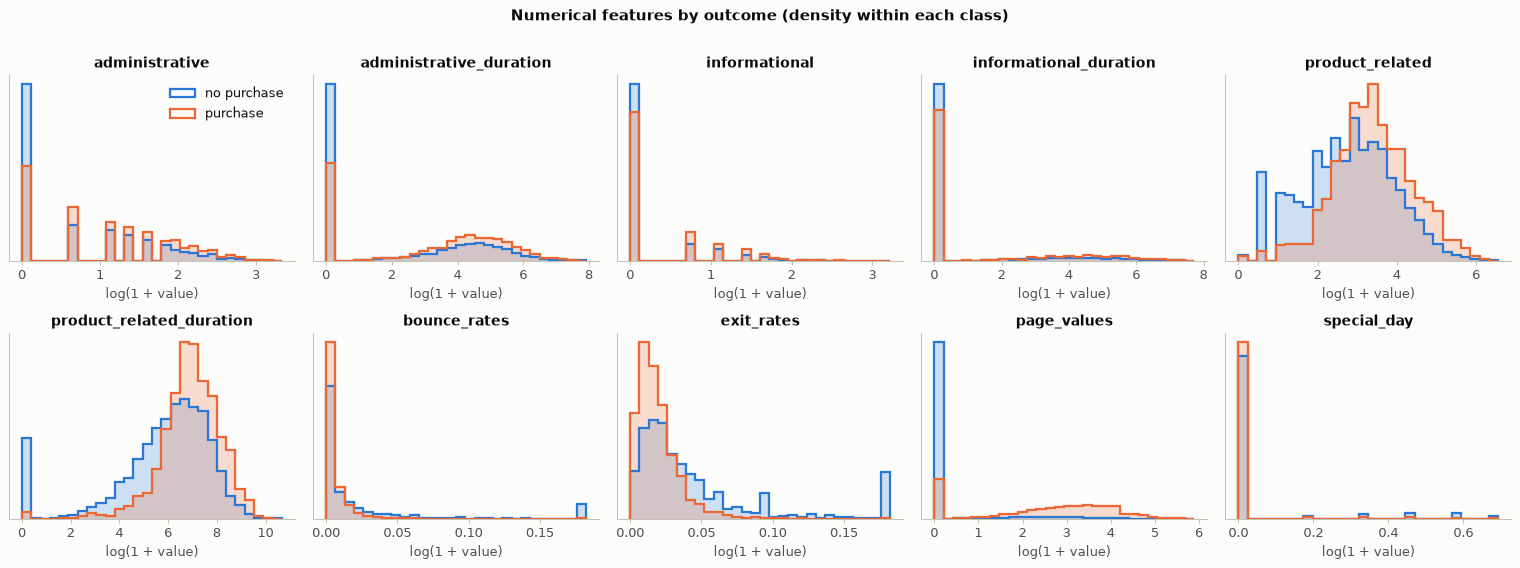

In [12]:
fig, axes = plt.subplots(2, 5, figsize=(17, 6.2))
for ax, column in zip(axes.ravel(), NUMERICAL_FEATURES):
    values = np.log1p(eda[column])
    bins = np.histogram_bin_edges(values, bins=28)
    for label, name, color in [(0, "no purchase", BLUE), (1, "purchase", ORANGE)]:
        subset = values[eda[TARGET] == label]
        ax.hist(subset, bins=bins, density=True, histtype="stepfilled", color=color, alpha=0.22)
        ax.hist(subset, bins=bins, density=True, histtype="step", color=color, linewidth=1.8, label=name)
    ax.set_title(column)
    ax.set_xlabel("log(1 + value)")
    ax.set_yticks([])
    ax.grid(False)
axes[0, 0].legend(loc="upper right")
fig.suptitle("Numerical features by outcome (density within each class)", fontweight="bold", y=1.01)
fig.tight_layout()
plt.show()

In [13]:
eda.groupby(TARGET)[NUMERICAL_FEATURES].median().T.rename(columns={0: "median, no purchase", 1: "median, purchase"})

revenue,"median, no purchase","median, purchase"
administrative,0.0000,2.0000
administrative_duration,0.0000,51.6042
informational,0.0000,0.0000
informational_duration,0.0000,0.0000
product_related,16.0000,28.0000
product_related_duration,501.5833,"1,081.8125"
bounce_rates,0.0040,0.0000
exit_rates,0.0286,0.0159
page_values,0.0000,16.5239
special_day,0.0000,0.0000


* Sessions that end with a purchase visit **more pages and last longer**, especially on
  product-related pages.
* They have **lower bounce and exit rates**.
* `page_values` separates the classes most clearly: its median is 0 for sessions without a
  purchase and clearly positive for sessions with one (see 5.3).
* `special_day` is 0 for most sessions.

### 4.3 Categorical features

Purchase rate per category. The dashed line is the overall purchase rate. Categories with
fewer than 50 sessions are drawn as outlines because their rates are very noisy.

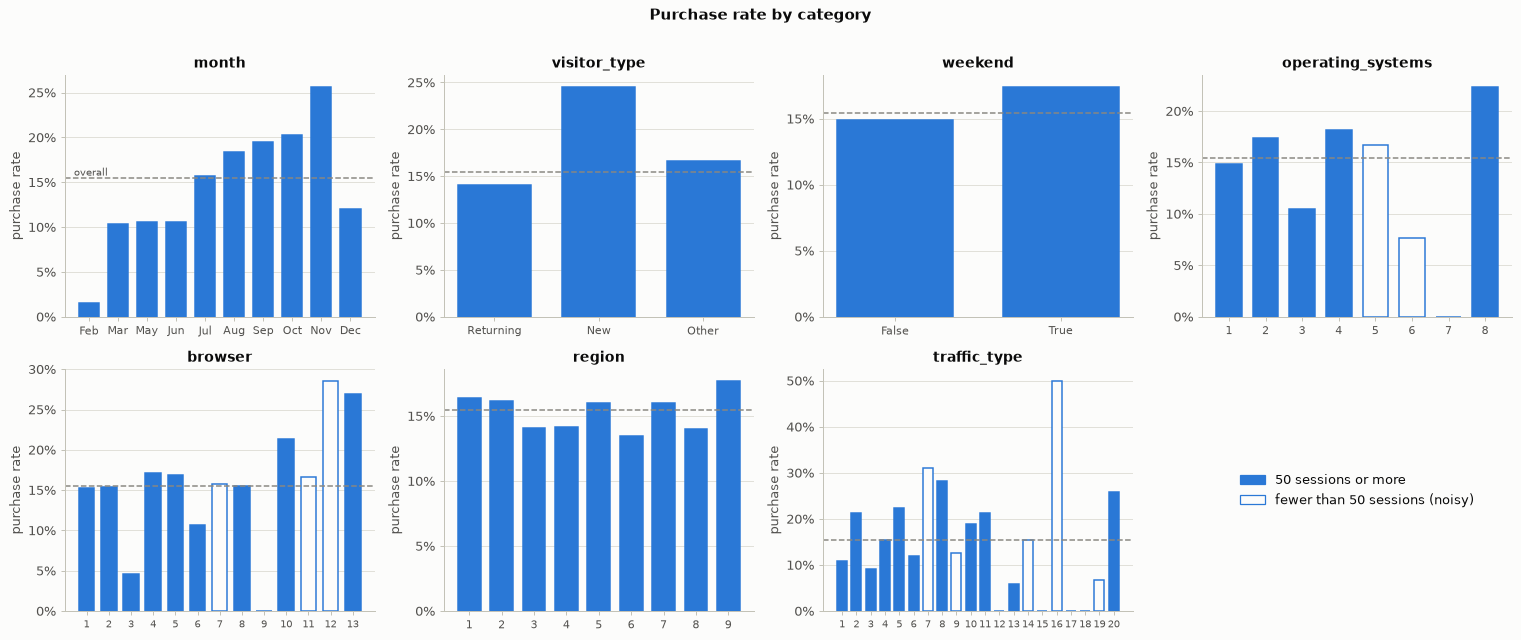

In [14]:
def category_table(frame: pd.DataFrame, column: str) -> pd.DataFrame:
    table = frame.groupby(column)[TARGET].agg(sessions="count", purchase_rate="mean")
    if column == "month":
        table = table.reindex([month for month in MONTHS if month in table.index])
    elif column in CODE_FEATURES:
        table = table.sort_index()
    else:
        table = table.sort_values("sessions", ascending=False)
    table["share of sessions"] = table["sessions"] / len(frame)
    return table


CATEGORY_COLUMNS = ["month", "visitor_type", "weekend"] + CODE_FEATURES
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, column in zip(axes.ravel(), CATEGORY_COLUMNS):
    table = category_table(eda, column)
    labels = [str(label).replace("_Visitor", "") for label in table.index]
    small = table["sessions"] < 50
    ax.bar(labels, table["purchase_rate"], color=[SURFACE if is_small else BLUE for is_small in small], edgecolor=BLUE, linewidth=1.2, width=0.7)
    ax.axhline(purchase_rate, color=MUTED, linestyle="--", linewidth=1.2)
    ax.set_title(column)
    ax.set_ylabel("purchase rate")
    ax.yaxis.set_major_locator(MaxNLocator(nbins=6, steps=[1, 2, 5, 10]))
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", labelsize=8 if len(labels) > 10 else 9)
axes[0, 0].text(0.02, purchase_rate, " overall", color=INK_SECONDARY, fontsize=8, va="bottom", transform=axes[0, 0].get_yaxis_transform())
legend_handles = [
    plt.Rectangle((0, 0), 1, 1, facecolor=BLUE, edgecolor=BLUE, label="50 sessions or more"),
    plt.Rectangle((0, 0), 1, 1, facecolor=SURFACE, edgecolor=BLUE, label="fewer than 50 sessions (noisy)"),
]
axes[1, 3].axis("off")
axes[1, 3].legend(handles=legend_handles, loc="center")
fig.suptitle("Purchase rate by category", fontweight="bold", y=1.01)
fig.tight_layout()
plt.show()

In [15]:
for column in ["month", "visitor_type", "weekend"]:
    display(category_table(eda, column))

,sessions,purchase_rate,share of sessions
month,,,
Feb,134,0.0149,0.0136
Mar,1539,0.1033,0.1560
May,2700,0.1059,0.2737
Jun,227,0.1057,0.0230
Jul,351,0.1567,0.0356
Aug,359,0.1838,0.0364
Sep,360,0.1944,0.0365
Oct,443,0.2032,0.0449
Nov,2372,0.2567,0.2405


,sessions,purchase_rate,share of sessions
visitor_type,,,
Returning_Visitor,8453,0.1402,0.8570
New_Visitor,1339,0.2457,0.1357
Other,72,0.1667,0.0073


,sessions,purchase_rate,share of sessions
weekend,,,
False,7582,0.1488,0.7687
True,2282,0.1744,0.2313


In [16]:
rare = {column: int((eda[column].value_counts() < 50).sum()) for column in CODE_FEATURES}
print("number of codes with fewer than 50 sessions:", rare)

number of codes with fewer than 50 sessions: {'operating_systems': 3, 'browser': 4, 'region': 0, 'traffic_type': 9}


* **Month** matters: the purchase rate is highest in November and lowest in February, with
  a clearly higher rate from September to November than in spring. Most sessions come from
  May, November, March and December.
* **New visitors** convert more often than returning visitors.
* **Weekend** sessions convert slightly more often than weekday sessions.
* `traffic_type` shows large differences between sources; `operating_systems`, `browser`
  and `region` show smaller ones.
* Several codes are rare. Their rates cannot be trusted, which is one reason to prefer
  regularised models (minimum leaf sizes for trees, a penalty for logistic regression).

### 4.4 Correlation between numerical features

Spearman (rank) correlation is used because the features are heavily skewed.

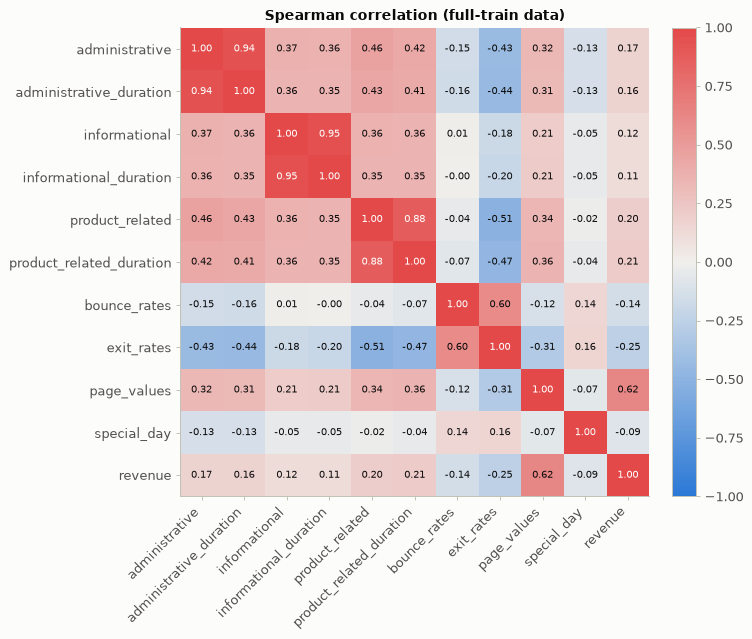

In [17]:
correlation = eda[NUMERICAL_FEATURES + [TARGET]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.6, 7.2))
image = ax.imshow(correlation, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation)), correlation.columns, rotation=45, ha="right")
ax.set_yticks(range(len(correlation)), correlation.index)
for i in range(len(correlation)):
    for j in range(len(correlation)):
        value = correlation.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8, color="#ffffff" if abs(value) > 0.75 else INK)
ax.grid(False)
ax.set_title("Spearman correlation (full-train data)")
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
plt.show()

* Each page count is strongly correlated with its duration, and `bounce_rates` with
  `exit_rates`. The features are partly redundant. This is harmless for tree ensembles; for
  logistic regression it makes individual coefficients harder to interpret, which is why
  regularisation strength is tuned.
* `page_values` has by far the strongest rank correlation with the target, followed by the
  (negative) exit rate and the product-related activity.

## 5. Feature importance analysis

Before training any model, each feature is scored on its own (as in modules 3 and 4 of the
course):

* **numerical features**: ROC AUC obtained when the raw feature value is used as the score.
  0.5 means "no information"; for features that are negatively related to the target the
  AUC of the negated feature is reported;
* **categorical features**: mutual information with the target.

The two measures have different scales, so they are shown in separate panels and should
only be compared within a panel.

### 5.1 Numerical features: single-feature ROC AUC

In [18]:
rows = []
for column in NUMERICAL_FEATURES:
    auc = roc_auc_score(eda[TARGET], eda[column])
    rows.append({"feature": column, "auc": max(auc, 1 - auc), "direction": "higher value → more purchases" if auc >= 0.5 else "higher value → fewer purchases"})
numeric_importance = pd.DataFrame(rows).sort_values("auc", ascending=False).reset_index(drop=True)
numeric_importance

,feature,auc,direction
0,page_values,0.8620,higher value → more purchases
1,exit_rates,0.7035,higher value → fewer purchases
2,product_related_duration,0.6704,higher value → more purchases
3,product_related,0.6562,higher value → more purchases
4,administrative,0.6258,higher value → more purchases
5,administrative_duration,0.6241,higher value → more purchases
6,bounce_rates,0.6097,higher value → fewer purchases
7,informational,0.5657,higher value → more purchases
8,informational_duration,0.5626,higher value → more purchases
9,special_day,0.5385,higher value → fewer purchases


### 5.2 Categorical features: mutual information

In [19]:
categorical_importance = (
    pd.Series({column: mutual_info_score(eda[column].astype(str), eda[TARGET]) for column in CATEGORICAL_FEATURES + ["weekend"]}, name="mutual information")
    .sort_values(ascending=False)
    .to_frame()
)
categorical_importance

,mutual information
month,0.0160
traffic_type,0.0152
visitor_type,0.0045
operating_systems,0.0033
browser,0.0012
region,0.0006
weekend,0.0004


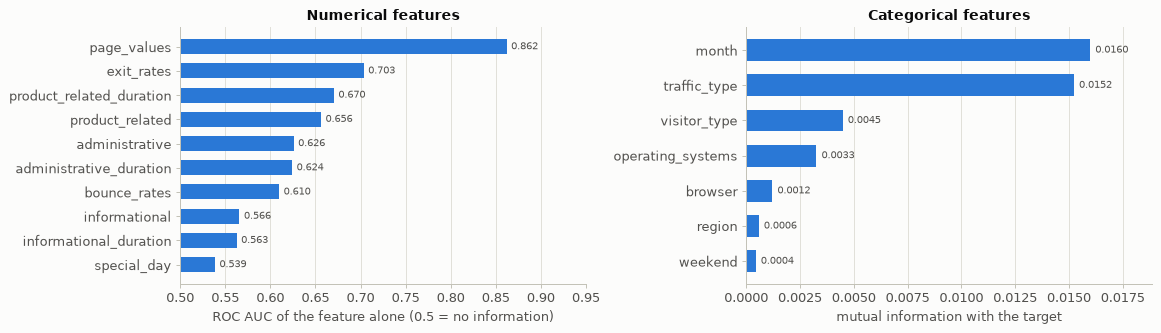

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
ordered = numeric_importance.sort_values("auc")
axes[0].barh(ordered["feature"], ordered["auc"] - 0.5, left=0.5, color=BLUE, height=0.62)
for y_position, value in enumerate(ordered["auc"]):
    axes[0].text(value + 0.005, y_position, f"{value:.3f}", va="center", fontsize=8, color=INK_SECONDARY)
axes[0].set_xlim(0.5, 0.95)
axes[0].set_xlabel("ROC AUC of the feature alone (0.5 = no information)")
axes[0].set_title("Numerical features")
axes[0].grid(axis="y", visible=False)

ordered = categorical_importance["mutual information"].sort_values()
axes[1].barh(ordered.index, ordered.values, color=BLUE, height=0.62)
for y_position, value in enumerate(ordered.values):
    axes[1].text(value + ordered.max() * 0.015, y_position, f"{value:.4f}", va="center", fontsize=8, color=INK_SECONDARY)
axes[1].set_xlim(0, ordered.max() * 1.18)
axes[1].set_xlabel("mutual information with the target")
axes[1].set_title("Categorical features")
axes[1].grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

### 5.3 A closer look at `page_values`

In [21]:
page_value_groups = (
    eda.assign(page_values_group=np.where(eda["page_values"] > 0, "page_values > 0", "page_values = 0"))
    .groupby("page_values_group")[TARGET]
    .agg(sessions="count", purchases="sum", purchase_rate="mean")
)
page_value_groups["share of sessions"] = page_value_groups["sessions"] / len(eda)
page_value_groups

,sessions,purchases,purchase_rate,share of sessions
page_values_group,,,,
page_values = 0,7681,299,0.0389,0.7787
page_values > 0,2183,1227,0.5621,0.2213


* `page_values` alone is a strong predictor. In Google Analytics a page gets a positive
  "page value" when visitors who viewed it went on to complete transactions, so a session
  has a positive average page value when it passed through pages that typically lead to
  purchases (for example the basket or the checkout). It is therefore expected to dominate,
  and the baseline in section 6 uses it alone to show how much the full models add.
* The exit rate and the amount of product-related and administrative browsing carry clear
  but weaker signals.
* Among categorical features, `month` and `traffic_type` are the most informative;
  `region` and `weekend` carry almost no information on their own.

Whether these impressions hold inside a multivariate model is checked in section 9.3 with
permutation importance for the final model.

## 6. Baselines and first models

Each session becomes a dictionary of features (`prepare_record`), and a `DictVectorizer`
one-hot encodes the categorical ones, as in the course.

In [22]:
records = {name: to_records(part) for name, part in [("train", df_train), ("val", df_val), ("full_train", df_full_train), ("test", df_test)]}
y = {name: part[TARGET].to_numpy() for name, part in [("train", df_train), ("val", df_val), ("full_train", df_full_train), ("test", df_test)]}

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(records["train"])
X_val = dv.transform(records["val"])
print("example record:", records["train"][0])
print(f"\n{X_train.shape[1]} columns after one-hot encoding")

example record: {'administrative': 7.0, 'administrative_duration': 238.4666667, 'informational': 7.0, 'informational_duration': 300.9, 'product_related': 33.0, 'product_related_duration': 1801.371429, 'bounce_rates': 0.0055, 'exit_rates': 0.040415616, 'page_values': 8.08269, 'special_day': 0.0, 'weekend': 1, 'month': 'May', 'visitor_type': 'Returning_Visitor', 'operating_systems': '2', 'browser': '1', 'region': '1', 'traffic_type': '4'}

71 columns after one-hot encoding


First pass with **default parameters**: fit on train, evaluate on validation. Two reference
points are included: a random ranking, and the single feature `page_values` used as the
score.

In [23]:
first_models = {
    "Logistic regression (scaled inputs)": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=SEED)),
    "Decision tree": DecisionTreeClassifier(random_state=SEED),
    "Random forest": RandomForestClassifier(random_state=SEED, n_jobs=-1),
    "XGBoost": XGBClassifier(random_state=SEED, n_jobs=1),
    "Gradient boosting (scikit-learn, histogram-based)": HistGradientBoostingClassifier(early_stopping=False, random_state=SEED),
}

rows = [
    {"model": "Random ranking (reference)", "train ROC AUC": 0.5, "validation ROC AUC": 0.5, "validation average precision": y["val"].mean()},
    {
        "model": "page_values alone (reference)",
        "train ROC AUC": roc_auc_score(y["train"], df_train["page_values"]),
        "validation ROC AUC": roc_auc_score(y["val"], df_val["page_values"]),
        "validation average precision": average_precision_score(y["val"], df_val["page_values"]),
    },
]
for name, model in first_models.items():
    model.fit(X_train, y["train"])
    rows.append(
        {
            "model": name,
            "train ROC AUC": roc_auc_score(y["train"], model.predict_proba(X_train)[:, 1]),
            "validation ROC AUC": roc_auc_score(y["val"], model.predict_proba(X_val)[:, 1]),
            "validation average precision": average_precision_score(y["val"], model.predict_proba(X_val)[:, 1]),
        }
    )
first_results = pd.DataFrame(rows).set_index("model")
first_results

,train ROC AUC,validation ROC AUC,validation average precision
model,,,
Random ranking (reference),0.5000,0.5000,0.1549
page_values alone (reference),0.8588,0.8714,0.6322
Logistic regression (scaled inputs),0.9012,0.8889,0.6439
Decision tree,1.0000,0.7294,0.3564
Random forest,1.0000,0.9284,0.7352
XGBoost,0.9998,0.9243,0.7062
"Gradient boosting (scikit-learn, histogram-based)",0.9943,0.9314,0.7334


* The single feature `page_values` is already a strong baseline; a useful model has to
  beat it.
* The unpruned **decision tree memorises the training data** (train AUC of 1.0) and
  generalises poorly. It needs depth and leaf-size limits.
* The tree ensembles are ahead of logistic regression out of the box, and all of them
  **overfit** with default settings (train AUC far above validation AUC), so tuning should
  mostly add regularisation.

## 7. Hyper-parameter tuning

All tuning uses **stratified 5-fold cross-validation on the full-train part** (the test set
is not touched). The folds are identical for every model, so results can be compared fold by
fold. The `DictVectorizer` is fitted inside each training fold. The selection metric is the
mean ROC AUC; average precision is reported next to it.

In [24]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
folds = []
for train_idx, val_idx in cv.split(records["full_train"], y["full_train"]):
    fold_dv = DictVectorizer(sparse=False)
    X_fold_train = fold_dv.fit_transform([records["full_train"][i] for i in train_idx])
    X_fold_val = fold_dv.transform([records["full_train"][i] for i in val_idx])
    folds.append((X_fold_train, y["full_train"][train_idx], X_fold_val, y["full_train"][val_idx], fold_dv))


def summarise(fold_auc, fold_ap) -> dict:
    return {
        "auc_mean": float(np.mean(fold_auc)),
        "auc_std": float(np.std(fold_auc)),
        "ap_mean": float(np.mean(fold_ap)),
        "ap_std": float(np.std(fold_ap)),
        "fold_auc": np.array(fold_auc),
    }


def cv_evaluate(make_model, prepare=None) -> dict:
    """Cross-validated ROC AUC and average precision of the model returned by `make_model()`."""
    fold_auc, fold_ap = [], []
    for X_fold_train, y_fold_train, X_fold_val, y_fold_val, fold_dv in folds:
        if prepare is not None:
            X_fold_train, X_fold_val = prepare(X_fold_train, fold_dv), prepare(X_fold_val, fold_dv)
        model = make_model().fit(X_fold_train, y_fold_train)
        probabilities = model.predict_proba(X_fold_val)[:, 1]
        fold_auc.append(roc_auc_score(y_fold_val, probabilities))
        fold_ap.append(average_precision_score(y_fold_val, probabilities))
    return summarise(fold_auc, fold_ap)


def best_of(results: pd.DataFrame) -> pd.Series:
    """Row with the highest mean cross-validated ROC AUC."""
    return results.sort_values("auc_mean", ascending=False, kind="stable").iloc[0]


tuned = {}  # model name -> best cross-validation result

### 7.1 Logistic regression (linear model)

Tuned: the regularisation strength `C` (smaller = stronger penalty) and whether the skewed
count / duration / page-value features are `log(1 + x)` transformed first. Inputs are
standardised.

In [25]:
LOG_FEATURES = [
    "administrative",
    "administrative_duration",
    "informational",
    "informational_duration",
    "product_related",
    "product_related_duration",
    "page_values",
]


def log_transform(X: np.ndarray, fold_dv: DictVectorizer) -> np.ndarray:
    X = X.copy()
    columns = [fold_dv.vocabulary_[feature] for feature in LOG_FEATURES]
    X[:, columns] = np.log1p(X[:, columns])
    return X


rows = []
for transform_name, prepare in [("raw", None), ("log1p", log_transform)]:
    for C in [0.001, 0.01, 0.1, 1, 10, 100]:
        result = cv_evaluate(lambda C=C: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000, random_state=SEED)), prepare)
        rows.append({"inputs": transform_name, "C": C, **result})
lr_results = pd.DataFrame(rows)
display(lr_results.pivot(index="C", columns="inputs", values="auc_mean").rename_axis(columns="mean CV ROC AUC by inputs"))

best = best_of(lr_results)
tuned["Logistic regression"] = {"params": {"inputs": best["inputs"], "C": float(best["C"])}, **best[["auc_mean", "auc_std", "ap_mean", "ap_std", "fold_auc"]].to_dict()}
print("best:", tuned["Logistic regression"]["params"], f"| CV ROC AUC = {best['auc_mean']:.4f} ± {best['auc_std']:.4f}")

mean CV ROC AUC by inputs,log1p,raw
C,,
0.0010,0.9136,0.8772
0.0100,0.9156,0.8890
0.1000,0.9135,0.8890
1.0000,0.9123,0.8880
10.0000,0.9120,0.8878
100.0000,0.9119,0.8878


best: {'inputs': 'log1p', 'C': 0.01} | CV ROC AUC = 0.9156 ± 0.0056


The log transform helps the linear model far more than the choice of `C`: the relation
between raw counts / durations and the log-odds of a purchase is not linear. Stronger
regularisation (small `C`) is slightly better, consistent with the correlated features seen
in 4.4.

### 7.2 Decision tree

Tuned: `max_depth` and `min_samples_leaf`.

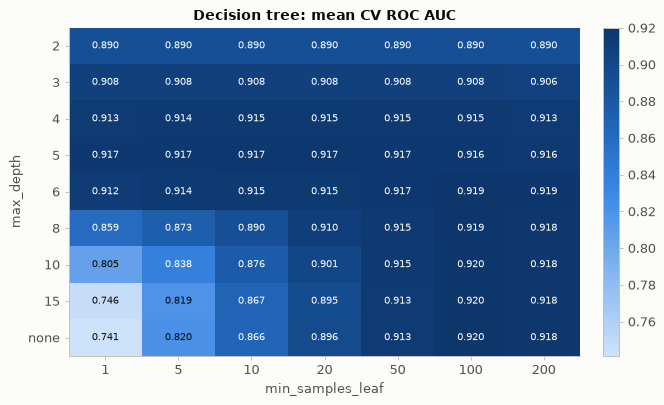

best: {'max_depth': 10, 'min_samples_leaf': 100} | CV ROC AUC = 0.9202 ± 0.0048


In [26]:
rows = []
for max_depth in [2, 3, 4, 5, 6, 8, 10, 15, None]:
    for min_samples_leaf in [1, 5, 10, 20, 50, 100, 200]:
        result = cv_evaluate(
            lambda max_depth=max_depth, min_samples_leaf=min_samples_leaf: DecisionTreeClassifier(
                max_depth=max_depth, min_samples_leaf=min_samples_leaf, random_state=SEED
            )
        )
        rows.append({"max_depth": max_depth, "max_depth_label": "none" if max_depth is None else str(max_depth), "min_samples_leaf": min_samples_leaf, **result})
dt_results = pd.DataFrame(rows)

depth_labels = ["2", "3", "4", "5", "6", "8", "10", "15", "none"]
dt_grid = dt_results.pivot(index="max_depth_label", columns="min_samples_leaf", values="auc_mean").loc[depth_labels]
fig, ax = plt.subplots(figsize=(7.5, 4.6))
image = ax.imshow(dt_grid, cmap=BLUES, aspect="auto")
ax.set_xticks(range(dt_grid.shape[1]), dt_grid.columns)
ax.set_yticks(range(dt_grid.shape[0]), dt_grid.index)
midpoint = (dt_grid.values.min() + dt_grid.values.max()) / 2
for i in range(dt_grid.shape[0]):
    for j in range(dt_grid.shape[1]):
        ax.text(j, i, f"{dt_grid.iloc[i, j]:.3f}", ha="center", va="center", fontsize=8, color="#ffffff" if dt_grid.iloc[i, j] > midpoint else INK)
ax.set_xlabel("min_samples_leaf")
ax.set_ylabel("max_depth")
ax.set_title("Decision tree: mean CV ROC AUC")
ax.grid(False)
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
fig.tight_layout()
plt.show()

best = best_of(dt_results)
tuned["Decision tree"] = {
    "params": {"max_depth": None if best["max_depth_label"] == "none" else int(best["max_depth_label"]), "min_samples_leaf": int(best["min_samples_leaf"])},
    **best[["auc_mean", "auc_std", "ap_mean", "ap_std", "fold_auc"]].to_dict(),
}
print("best:", tuned["Decision tree"]["params"], f"| CV ROC AUC = {best['auc_mean']:.4f} ± {best['auc_std']:.4f}")

Deep trees with small leaves overfit badly (bottom-left corner). Requiring large leaves is
the most effective regulariser for a single tree on this data.

### 7.3 Random forest

Tuned with 200 trees: `max_features` (features tried at each split), `max_depth` and
`min_samples_leaf`. The best configuration is then re-evaluated with 500 trees.

In [27]:
rows = []
for max_features in ["sqrt", 0.3]:
    for max_depth in [10, None]:
        for min_samples_leaf in [1, 5, 10, 20]:
            result = cv_evaluate(
                lambda max_features=max_features, max_depth=max_depth, min_samples_leaf=min_samples_leaf: RandomForestClassifier(
                    n_estimators=200, max_features=max_features, max_depth=max_depth, min_samples_leaf=min_samples_leaf, random_state=SEED, n_jobs=-1
                )
            )
            rows.append(
                {
                    "max_features": str(max_features),
                    "max_depth": "none" if max_depth is None else str(max_depth),
                    "min_samples_leaf": min_samples_leaf,
                    **result,
                }
            )
rf_results = pd.DataFrame(rows)
display(
    rf_results.pivot(index=["max_features", "max_depth"], columns="min_samples_leaf", values="auc_mean").rename_axis(
        columns="mean CV ROC AUC by min_samples_leaf"
    )
)

best = best_of(rf_results)
rf_params = {
    "max_features": "sqrt" if best["max_features"] == "sqrt" else float(best["max_features"]),
    "max_depth": None if best["max_depth"] == "none" else int(best["max_depth"]),
    "min_samples_leaf": int(best["min_samples_leaf"]),
}
print("best with 200 trees:", rf_params, f"| CV ROC AUC = {best['auc_mean']:.4f} ± {best['auc_std']:.4f}")

result = cv_evaluate(lambda: RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=-1, **rf_params))
tuned["Random forest"] = {"params": {"n_estimators": 500, **rf_params}, **result}
print(f"same configuration with 500 trees: CV ROC AUC = {result['auc_mean']:.4f} ± {result['auc_std']:.4f}")

mean CV ROC AUC by min_samples_leaf     1      5      10     20
max_features max_depth                                         
0.3          10                     0.9309 0.9316 0.9325 0.9319
             none                   0.9259 0.9306 0.9322 0.9316
sqrt         10                     0.9243 0.9243 0.9238 0.9224
             none                   0.9253 0.9267 0.9257 0.9235

best with 200 trees: {'max_features': 0.3, 'max_depth': 10, 'min_samples_leaf': 10} | CV ROC AUC = 0.9325 ± 0.0034


same configuration with 500 trees: CV ROC AUC = 0.9325 ± 0.0032


Looking at more features per split (`max_features=0.3` instead of the square-root default)
helps most, and with that setting moderately larger leaves help a little more. A likely
reason: after one-hot encoding there are 71 columns, so the square-root rule offers only
about 8 of them at each split and the dominant feature `page_values` is often not among
them. Going from 200 to 500 trees does not change the score.

### 7.4 XGBoost

Tuned step by step, as in the course: first the learning rate `eta`, then `max_depth`, then
`min_child_weight`. For every setting 800 trees are trained once per fold and the model is
evaluated after 25, 50, ..., 800 trees, which gives the best number of trees for free.

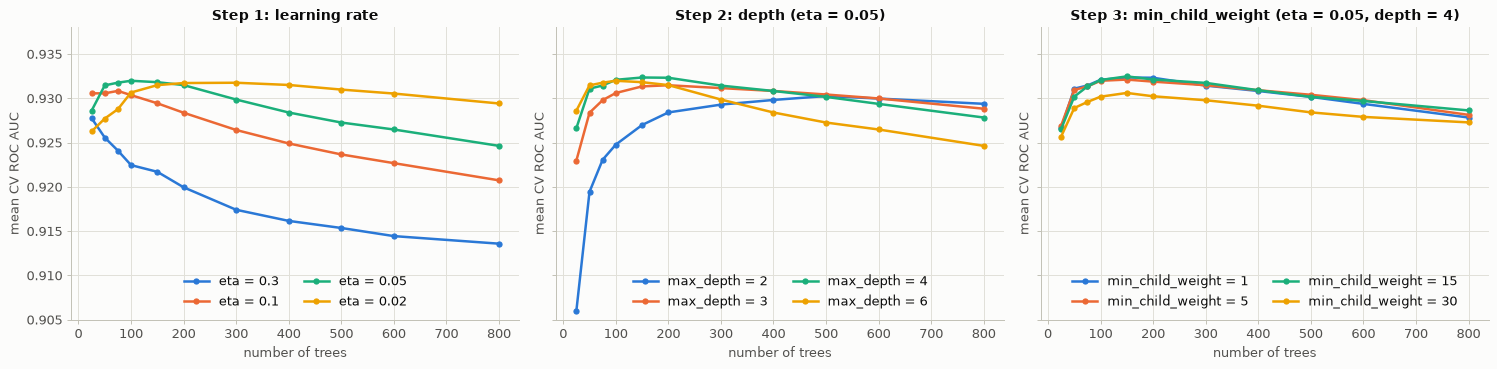

,eta,max_depth,min_child_weight,n_estimators,auc_mean,auc_std,ap_mean
step,,,,,,,
1. eta,0.0500,6,1,100,0.9320,0.0036,0.7431
2. max_depth,0.0500,4,1,150,0.9324,0.0045,0.7491
3. min_child_weight,0.0500,4,15,150,0.9325,0.0040,0.7489


best: {'eta': 0.05, 'max_depth': 4, 'min_child_weight': 15, 'n_estimators': 150} | CV ROC AUC = 0.9325 ± 0.0040


In [28]:
XGB_CHECKPOINTS = [25, 50, 75, 100, 150, 200, 300, 400, 500, 600, 800]
xgb_cache = {}


def xgb_cv(eta: float, max_depth: int, min_child_weight: int) -> pd.DataFrame:
    key = (eta, max_depth, min_child_weight)
    if key not in xgb_cache:
        fold_auc = {n: [] for n in XGB_CHECKPOINTS}
        fold_ap = {n: [] for n in XGB_CHECKPOINTS}
        for X_fold_train, y_fold_train, X_fold_val, y_fold_val, _ in folds:
            model = XGBClassifier(
                n_estimators=XGB_CHECKPOINTS[-1],
                learning_rate=eta,
                max_depth=max_depth,
                min_child_weight=min_child_weight,
                tree_method="hist",
                random_state=SEED,
                n_jobs=1,
            ).fit(X_fold_train, y_fold_train)
            for n in XGB_CHECKPOINTS:
                probabilities = model.predict_proba(X_fold_val, iteration_range=(0, n))[:, 1]
                fold_auc[n].append(roc_auc_score(y_fold_val, probabilities))
                fold_ap[n].append(average_precision_score(y_fold_val, probabilities))
        xgb_cache[key] = pd.DataFrame(
            [{"eta": eta, "max_depth": max_depth, "min_child_weight": min_child_weight, "n_estimators": n, **summarise(fold_auc[n], fold_ap[n])} for n in XGB_CHECKPOINTS]
        )
    return xgb_cache[key]


def plot_curves(ax, curves: dict, x: str, title: str) -> None:
    for (label, curve), color in zip(curves.items(), SERIES):
        ax.plot(curve[x], curve["auc_mean"], color=color, marker="o", markersize=4, label=label)
    ax.set_xlabel("number of trees")
    ax.set_ylabel("mean CV ROC AUC")
    ax.set_title(title)
    ax.legend(loc="lower center", ncol=2)


# Step 1: learning rate (XGBoost defaults for the rest: max_depth=6, min_child_weight=1)
eta_curves = {f"eta = {eta}": xgb_cv(eta, 6, 1) for eta in [0.3, 0.1, 0.05, 0.02]}
best_eta = float(best_of(pd.concat(eta_curves.values()))["eta"])

# Step 2: tree depth
depth_curves = {f"max_depth = {depth}": xgb_cv(best_eta, depth, 1) for depth in [2, 3, 4, 6]}
best_depth = int(best_of(pd.concat(depth_curves.values()))["max_depth"])

# Step 3: minimum child weight
weight_curves = {f"min_child_weight = {weight}": xgb_cv(best_eta, best_depth, weight) for weight in [1, 5, 15, 30]}
best = best_of(pd.concat(weight_curves.values()))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), sharey=True)
plot_curves(axes[0], eta_curves, "n_estimators", "Step 1: learning rate")
plot_curves(axes[1], depth_curves, "n_estimators", f"Step 2: depth (eta = {best_eta})")
plot_curves(axes[2], weight_curves, "n_estimators", f"Step 3: min_child_weight (eta = {best_eta}, depth = {best_depth})")
axes[0].set_ylim(0.905, 0.938)
fig.tight_layout()
plt.show()

xgb_steps = pd.DataFrame(
    [
        {"step": name, **best_of(pd.concat(curves.values()))[["eta", "max_depth", "min_child_weight", "n_estimators", "auc_mean", "auc_std", "ap_mean"]].to_dict()}
        for name, curves in [("1. eta", eta_curves), ("2. max_depth", depth_curves), ("3. min_child_weight", weight_curves)]
    ]
).set_index("step")
display(xgb_steps)

tuned["XGBoost"] = {
    "params": {"eta": float(best["eta"]), "max_depth": int(best["max_depth"]), "min_child_weight": int(best["min_child_weight"]), "n_estimators": int(best["n_estimators"])},
    **best[["auc_mean", "auc_std", "ap_mean", "ap_std", "fold_auc"]].to_dict(),
}
print("best:", tuned["XGBoost"]["params"], f"| CV ROC AUC = {best['auc_mean']:.4f} ± {best['auc_std']:.4f}")

* A large learning rate (`eta = 0.3`) overfits after a few dozen trees; smaller learning
  rates reach a slightly higher and much flatter optimum.
* Trees of depth 3 to 4 are marginally better than the default depth of 6; very shallow
  trees (depth 2) need many more rounds and stay behind.
* `min_child_weight` changes little, except that the largest value is slightly worse.

### 7.5 Gradient boosting in scikit-learn (`HistGradientBoostingClassifier`)

The same family of model as XGBoost (boosted trees built on histograms), but it ships with
scikit-learn. Tuned on a full grid: `learning_rate`, `max_leaf_nodes` (tree size) and
`min_samples_leaf`, with the number of boosting iterations read off the same kind of curve
(300 iterations are trained once per fold and evaluated at 25, 50, 75, 100, 150, ..., 300).

In [29]:
HGB_CHECKPOINTS = [25, 50, 75, 100, 150, 200, 250, 300]


def hgb_cv(learning_rate: float, max_leaf_nodes: int, min_samples_leaf: int) -> pd.DataFrame:
    fold_auc = {n: [] for n in HGB_CHECKPOINTS}
    fold_ap = {n: [] for n in HGB_CHECKPOINTS}
    for X_fold_train, y_fold_train, X_fold_val, y_fold_val, _ in folds:
        model = HistGradientBoostingClassifier(
            max_iter=HGB_CHECKPOINTS[-1],
            learning_rate=learning_rate,
            max_leaf_nodes=max_leaf_nodes,
            min_samples_leaf=min_samples_leaf,
            early_stopping=False,
            random_state=SEED,
        ).fit(X_fold_train, y_fold_train)
        for n, probabilities in enumerate(model.staged_predict_proba(X_fold_val), start=1):
            if n in fold_auc:
                fold_auc[n].append(roc_auc_score(y_fold_val, probabilities[:, 1]))
                fold_ap[n].append(average_precision_score(y_fold_val, probabilities[:, 1]))
    return pd.DataFrame(
        [
            {"learning_rate": learning_rate, "max_leaf_nodes": max_leaf_nodes, "min_samples_leaf": min_samples_leaf, "max_iter": n, **summarise(fold_auc[n], fold_ap[n])}
            for n in HGB_CHECKPOINTS
        ]
    )


hgb_results = pd.concat(
    [hgb_cv(learning_rate, max_leaf_nodes, min_samples_leaf) for learning_rate in [0.1, 0.05] for max_leaf_nodes in [4, 8, 16, 31] for min_samples_leaf in [20, 50, 100]],
    ignore_index=True,
)

# Best number of iterations for every combination of the other parameters
hgb_best_per_config = (
    hgb_results.sort_values("auc_mean", ascending=False, kind="stable")
    .groupby(["learning_rate", "max_leaf_nodes", "min_samples_leaf"], as_index=False)
    .first()
    .sort_values("auc_mean", ascending=False)
    .reset_index(drop=True)
)
display(hgb_best_per_config.drop(columns="fold_auc"))

best = best_of(hgb_results)
best_hgb_params = {
    "learning_rate": float(best["learning_rate"]),
    "max_iter": int(best["max_iter"]),
    "max_leaf_nodes": int(best["max_leaf_nodes"]),
    "min_samples_leaf": int(best["min_samples_leaf"]),
}
tuned["Gradient boosting (scikit-learn)"] = {"params": best_hgb_params, **best[["auc_mean", "auc_std", "ap_mean", "ap_std", "fold_auc"]].to_dict()}
print("best:", best_hgb_params, f"| CV ROC AUC = {best['auc_mean']:.4f} ± {best['auc_std']:.4f}")

,learning_rate,max_leaf_nodes,min_samples_leaf,max_iter,auc_mean,auc_std,ap_mean,ap_std
0,0.0500,16,50,75,0.9337,0.0044,0.7474,0.0122
1,0.1000,16,50,50,0.9337,0.0043,0.7483,0.0110
2,0.0500,8,20,150,0.9335,0.0037,0.7478,0.0125
3,0.0500,16,100,75,0.9335,0.0047,0.7483,0.0164
4,0.1000,16,20,50,0.9334,0.0040,0.7497,0.0094
5,0.0500,16,20,75,0.9333,0.0038,0.7480,0.0118
6,0.0500,8,50,100,0.9333,0.0039,0.7449,0.0137
7,0.1000,8,20,50,0.9331,0.0030,0.7446,0.0120
8,0.1000,16,100,50,0.9331,0.0048,0.7499,0.0167
9,0.0500,8,100,150,0.9331,0.0045,0.7483,0.0159


best: {'learning_rate': 0.05, 'max_iter': 75, 'max_leaf_nodes': 16, 'min_samples_leaf': 50} | CV ROC AUC = 0.9337 ± 0.0044


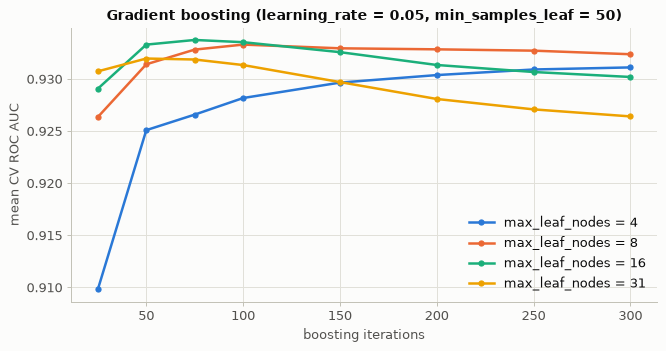

In [30]:
fig, ax = plt.subplots(figsize=(7.5, 4))
best_learning_rate, best_min_leaf = best_hgb_params["learning_rate"], best_hgb_params["min_samples_leaf"]
for max_leaf_nodes, color in zip([4, 8, 16, 31], SERIES):
    curve = hgb_results[
        (hgb_results["learning_rate"] == best_learning_rate) & (hgb_results["max_leaf_nodes"] == max_leaf_nodes) & (hgb_results["min_samples_leaf"] == best_min_leaf)
    ]
    ax.plot(curve["max_iter"], curve["auc_mean"], color=color, marker="o", markersize=4, label=f"max_leaf_nodes = {max_leaf_nodes}")
ax.set_xlabel("boosting iterations")
ax.set_ylabel("mean CV ROC AUC")
ax.set_title(f"Gradient boosting (learning_rate = {best_learning_rate}, min_samples_leaf = {best_min_leaf})")
ax.legend()
fig.tight_layout()
plt.show()

* The table lists, for every combination, its best number of iterations. Medium-sized
  trees (16 leaves) with the smaller learning rate come out on top, and the optimum lies
  inside the grid for tree size, leaf size and number of iterations.
* The ten best combinations differ by less than 0.001 in ROC AUC, far less than the spread
  between folds (about 0.004), so the model is not sensitive to the exact setting. The
  smallest trees (4 leaves, which need many more iterations) and the largest ones
  (31 leaves, which overfit after a few dozen iterations) are slightly behind.
* Learning rate and number of iterations trade off against each other, as with XGBoost:
  larger trees and larger learning rates peak earlier and then start to overfit.

## 8. Model selection

Best configuration of each model family, evaluated on the same five folds.

In [31]:
comparison = pd.DataFrame(
    [
        {
            "model": name,
            "CV ROC AUC (mean)": result["auc_mean"],
            "CV ROC AUC (std)": result["auc_std"],
            "CV average precision (mean)": result["ap_mean"],
            "CV average precision (std)": result["ap_std"],
            "best parameters": result["params"],
        }
        for name, result in tuned.items()
    ]
).set_index("model").sort_values("CV ROC AUC (mean)", ascending=False)
with pd.option_context("display.max_colwidth", 120):
    display(comparison)

,CV ROC AUC (mean),CV ROC AUC (std),CV average precision (mean),CV average precision (std),best parameters
model,,,,,
Gradient boosting (scikit-learn),0.9337,0.0044,0.7474,0.0122,"{'learning_rate': 0.05, 'max_iter': 75, 'max_leaf_nodes': 16, 'min_samples_leaf': 50}"
XGBoost,0.9325,0.0040,0.7489,0.0116,"{'eta': 0.05, 'max_depth': 4, 'min_child_weight': 15, 'n_estimators': 150}"
Random forest,0.9325,0.0032,0.7500,0.0130,"{'n_estimators': 500, 'max_features': 0.3, 'max_depth': 10, 'min_samples_leaf': 10}"
Decision tree,0.9202,0.0048,0.7019,0.0093,"{'max_depth': 10, 'min_samples_leaf': 100}"
Logistic regression,0.9156,0.0056,0.6788,0.0319,"{'inputs': 'log1p', 'C': 0.01}"


In [32]:
winner = comparison.index[0]
fold_table = pd.DataFrame({name: tuned[name]["fold_auc"] for name in comparison.index}, index=[f"fold {i}" for i in range(1, N_SPLITS + 1)]).T
fold_table["mean"] = fold_table.mean(axis=1)
differences = pd.DataFrame(
    {
        "mean difference to the best model": [float(np.mean(tuned[winner]["fold_auc"] - tuned[name]["fold_auc"])) for name in comparison.index],
        "standard error of the difference": [
            float(np.std(tuned[winner]["fold_auc"] - tuned[name]["fold_auc"], ddof=1) / np.sqrt(N_SPLITS)) for name in comparison.index
        ],
        "folds where the best model is ahead": [int(np.sum(tuned[winner]["fold_auc"] > tuned[name]["fold_auc"])) for name in comparison.index],
    },
    index=comparison.index,
).drop(index=winner)
differences["difference / standard error"] = differences["mean difference to the best model"] / differences["standard error of the difference"]
print("ROC AUC per fold")
display(fold_table)
print(f"Paired comparison with the best model ({winner})")
display(differences)

ROC AUC per fold


,fold 1,fold 2,fold 3,fold 4,fold 5,mean
Gradient boosting (scikit-learn),0.9354,0.9310,0.9353,0.9400,0.9270,0.9337
XGBoost,0.9322,0.9312,0.9351,0.9379,0.9260,0.9325
Random forest,0.9340,0.9328,0.9342,0.9350,0.9263,0.9325
Decision tree,0.9149,0.9213,0.9263,0.9241,0.9144,0.9202
Logistic regression,0.9136,0.9183,0.9177,0.9224,0.9059,0.9156


Paired comparison with the best model (Gradient boosting (scikit-learn))


,mean difference to the best model,standard error of the difference,folds where the best model is ahead,difference / standard error
model,,,,
XGBoost,0.0013,0.0006,4,2.0117
Random forest,0.0013,0.0011,4,1.1598
Decision tree,0.0136,0.0021,5,6.3992
Logistic regression,0.0182,0.0016,5,11.1991


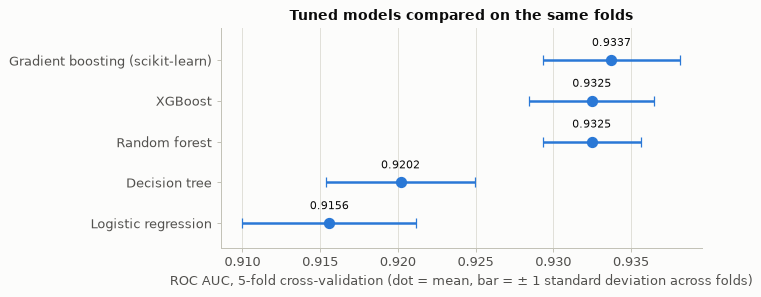

In [33]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ordered = comparison.iloc[::-1]
positions = np.arange(len(ordered))
ax.errorbar(ordered["CV ROC AUC (mean)"], positions, xerr=ordered["CV ROC AUC (std)"], fmt="o", color=BLUE, ecolor=BLUE, elinewidth=2, capsize=4, markersize=8)
for position, (mean, std) in enumerate(zip(ordered["CV ROC AUC (mean)"], ordered["CV ROC AUC (std)"])):
    ax.text(mean, position + 0.28, f"{mean:.4f}", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_yticks(positions, ordered.index)
ax.set_ylim(-0.6, len(ordered) - 0.2)
ax.set_xlabel("ROC AUC, 5-fold cross-validation (dot = mean, bar = ± 1 standard deviation across folds)")
ax.set_title("Tuned models compared on the same folds")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "model_comparison.png", bbox_inches="tight")
plt.show()

**Decision.** The model with the highest mean cross-validated ROC AUC is selected:
**gradient boosting from scikit-learn (`HistGradientBoostingClassifier`)**.

The honest reading of the tables is that the three tuned tree ensembles (gradient boosting,
XGBoost, random forest) **cannot be separated with five folds**:

* their mean differences in ROC AUC are about 0.001, which is one to two standard errors of
  the paired difference. A paired t-test with five folds needs a ratio of about 2.8 for
  significance at the 5% level (and such a test is only approximate, because the folds
  share training data);
* gradient boosting is not ahead on every fold;
* by average precision the order of the three is reversed, again with differences far
  below the spread between folds.

All three are clearly ahead of the single decision tree and of logistic regression (ahead on
every fold, by more than six standard errors).

Between tied models, practical properties decide, and they point the same way as the mean
score:

* the scikit-learn model needs **no extra dependency in the web service** (on Linux, XGBoost
  would add several hundred MB of native libraries to the Docker image);
* the saved model is tiny (75 small trees, under 0.2 MB as `model.bin`), whereas the random
  forest stores 500 trees of depth up to 10.

The selected parameters are hard-coded in `train.py` as `FINAL_PARAMS`. The next cell fails
if the script and the tuning results above ever disagree.

In [34]:
assert best_hgb_params == FINAL_PARAMS, f"train.py uses {FINAL_PARAMS}, but tuning selected {best_hgb_params}"
print("train.py FINAL_PARAMS match the tuning result:", FINAL_PARAMS)

train.py FINAL_PARAMS match the tuning result: {'learning_rate': 0.05, 'max_iter': 75, 'max_leaf_nodes': 16, 'min_samples_leaf': 50}


## 9. Final model

### 9.1 Decision threshold

The model outputs a probability. To turn it into a yes/no flag a threshold is needed, and
with imbalanced classes 0.5 is rarely the right choice. The threshold is chosen on
**out-of-fold predictions** of the full-train part (each session is scored by a model that
did not see it), never on the test set. As a neutral default the threshold that maximises
**F1** is used, searched over 0.01, 0.02, ..., 0.99 as in module 4 of the course
(`choose_threshold` in `train.py`). The table shows the trade-off, so that a different
operating point can be picked for a specific business use (see the README).

In [35]:
out_of_fold = np.zeros(len(y["full_train"]))
for train_idx, val_idx in cv.split(records["full_train"], y["full_train"]):
    fold_pipeline = build_pipeline(best_hgb_params)
    fold_pipeline.fit([records["full_train"][i] for i in train_idx], y["full_train"][train_idx])
    out_of_fold[val_idx] = fold_pipeline.predict_proba([records["full_train"][i] for i in val_idx])[:, 1]

threshold = choose_threshold(y["full_train"], out_of_fold)
print(f"out-of-fold ROC AUC = {roc_auc_score(y['full_train'], out_of_fold):.4f} | average precision = {average_precision_score(y['full_train'], out_of_fold):.4f}")
print(f"threshold that maximises F1 on out-of-fold predictions: {threshold:.2f}")

threshold_table = pd.DataFrame(
    [
        {**classification_report_at(y["full_train"], out_of_fold, t), "share of sessions flagged": float(np.mean(out_of_fold >= t))}
        for t in sorted({0.1, 0.2, 0.3, 0.5, 0.7, threshold})
    ]
)[["threshold", "precision", "recall", "f1", "share of sessions flagged"]]
threshold_table

out-of-fold ROC AUC = 0.9334 | average precision = 0.7457
threshold that maximises F1 on out-of-fold predictions: 0.33


,threshold,precision,recall,f1,share of sessions flagged
0,0.1000,0.4634,0.8991,0.6115,0.3002
1,0.2000,0.5515,0.8211,0.6598,0.2303
2,0.3000,0.6167,0.7516,0.6775,0.1886
3,0.3300,0.6435,0.7333,0.6855,0.1763
4,0.5000,0.7248,0.5990,0.6559,0.1278
5,0.7000,0.8401,0.3683,0.5121,0.0678


### 9.2 Evaluation on the held-out test set

The final model is trained on the full-train part (80%) and evaluated **once** on the test
set (20%), which played no role in any decision above. Confidence intervals come from 1,000
bootstrap resamples of the test set.

In [36]:
final_pipeline = build_pipeline(best_hgb_params).fit(records["full_train"], y["full_train"])
test_probabilities = final_pipeline.predict_proba(records["test"])[:, 1]

test_auc = roc_auc_score(y["test"], test_probabilities)
test_ap = average_precision_score(y["test"], test_probabilities)
test_brier = brier_score_loss(y["test"], test_probabilities)

rng = np.random.default_rng(SEED)
boot_auc, boot_ap = [], []
for _ in range(1000):
    sample = rng.integers(0, len(y["test"]), len(y["test"]))
    boot_auc.append(roc_auc_score(y["test"][sample], test_probabilities[sample]))
    boot_ap.append(average_precision_score(y["test"][sample], test_probabilities[sample]))
auc_low, auc_high = np.percentile(boot_auc, [2.5, 97.5])
ap_low, ap_high = np.percentile(boot_ap, [2.5, 97.5])

print(f"test ROC AUC           = {test_auc:.4f}   (95% bootstrap interval {auc_low:.4f} to {auc_high:.4f})")
print(f"test average precision = {test_ap:.4f}   (95% bootstrap interval {ap_low:.4f} to {ap_high:.4f}; random ranking = {y['test'].mean():.4f})")
print(f"test Brier score       = {test_brier:.4f}   (always predicting the base rate = {np.mean((y['test'] - y['full_train'].mean()) ** 2):.4f})")

test_report = classification_report_at(y["test"], test_probabilities, threshold)
print(f"\nat threshold {threshold:.2f}: precision = {test_report['precision']:.4f} | recall = {test_report['recall']:.4f} | F1 = {test_report['f1']:.4f}")
confusion = pd.DataFrame(
    [[test_report["tn"], test_report["fp"]], [test_report["fn"], test_report["tp"]]],
    index=["actual: no purchase", "actual: purchase"],
    columns=["predicted: no purchase", "predicted: purchase"],
)
confusion

test ROC AUC           = 0.9401   (95% bootstrap interval 0.9285 to 0.9498)
test average precision = 0.7801   (95% bootstrap interval 0.7394 to 0.8150; random ranking = 0.1549)
test Brier score       = 0.0651   (always predicting the base rate = 0.1309)

at threshold 0.33: precision = 0.6568 | recall = 0.7565 | F1 = 0.7032


,predicted: no purchase,predicted: purchase
actual: no purchase,1933,151
actual: purchase,93,289


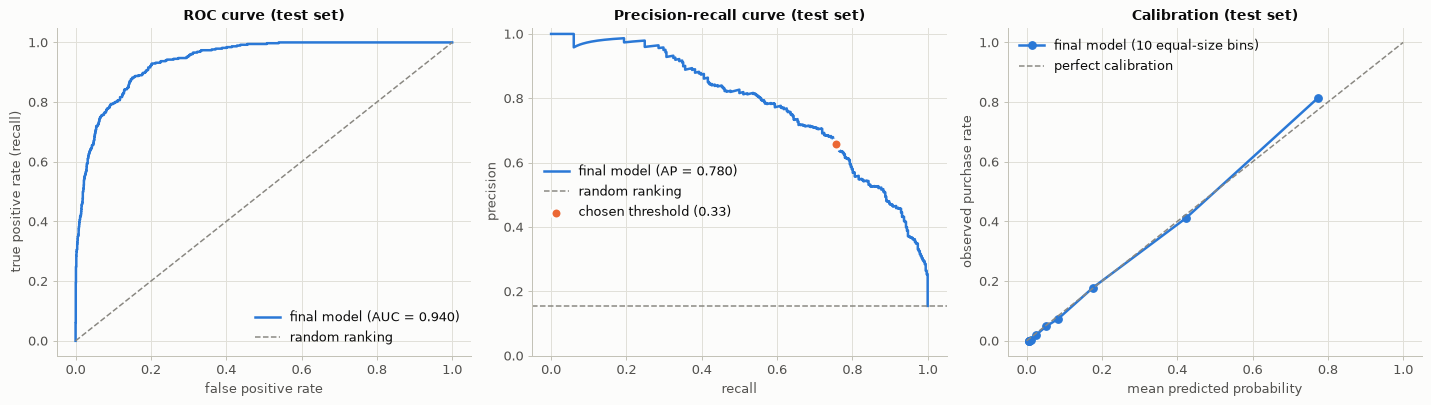

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

false_positive_rate, true_positive_rate, _ = roc_curve(y["test"], test_probabilities)
axes[0].plot(false_positive_rate, true_positive_rate, color=BLUE, label=f"final model (AUC = {test_auc:.3f})")
axes[0].plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1.2, label="random ranking")
axes[0].set_xlabel("false positive rate")
axes[0].set_ylabel("true positive rate (recall)")
axes[0].set_title("ROC curve (test set)")
axes[0].legend(loc="lower right")

precision, recall, _ = precision_recall_curve(y["test"], test_probabilities)
axes[1].plot(recall, precision, color=BLUE, label=f"final model (AP = {test_ap:.3f})")
axes[1].axhline(y["test"].mean(), color=MUTED, linestyle="--", linewidth=1.2, label="random ranking")
axes[1].scatter([test_report["recall"]], [test_report["precision"]], color=ORANGE, s=70, zorder=3, edgecolor=SURFACE, linewidth=2, label=f"chosen threshold ({threshold:.2f})")
axes[1].set_xlabel("recall")
axes[1].set_ylabel("precision")
axes[1].set_ylim(0, 1.02)
axes[1].set_title("Precision-recall curve (test set)")
axes[1].legend(loc="center left")

observed, predicted = calibration_curve(y["test"], test_probabilities, n_bins=10, strategy="quantile")
axes[2].plot(predicted, observed, color=BLUE, marker="o", markersize=6, label="final model (10 equal-size bins)")
axes[2].plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1.2, label="perfect calibration")
axes[2].set_xlabel("mean predicted probability")
axes[2].set_ylabel("observed purchase rate")
axes[2].set_title("Calibration (test set)")
axes[2].legend(loc="upper left")

fig.tight_layout()
fig.savefig(IMAGES_DIR / "test_evaluation.png", bbox_inches="tight")
plt.show()

* The test-set scores are a little higher than the cross-validation means (ROC AUC 0.940
  against 0.934, average precision 0.780 against 0.747), and both cross-validation means lie
  inside the bootstrap intervals. There is no sign that tuning overfitted the folds.
* The predicted probabilities follow the observed purchase rates closely, and the Brier
  score is half that of always predicting the base rate, so the output can be read as a
  probability.
* At the F1-optimal threshold the model finds about three out of four purchasing sessions
  (recall 0.76), and about two out of three flagged sessions really end with a purchase
  (precision 0.66).

### 9.3 Feature importance of the final model

**Permutation importance**: the values of one original feature are shuffled across the test
sessions (before one-hot encoding, so a categorical feature is permuted as a whole) and the
drop in ROC AUC is recorded, averaged over 10 shuffles. This is a diagnostic of the finished
model; it is not used for any selection.

In [38]:
def permutation_importance(pipeline, feature_records, targets, n_repeats: int = 10) -> pd.DataFrame:
    generator = np.random.default_rng(SEED)
    baseline = roc_auc_score(targets, pipeline.predict_proba(feature_records)[:, 1])
    rows = []
    for feature in FEATURES:
        values = [record[feature] for record in feature_records]
        drops = []
        for _ in range(n_repeats):
            order = generator.permutation(len(feature_records))
            shuffled = [{**record, feature: values[j]} for record, j in zip(feature_records, order)]
            drops.append(baseline - roc_auc_score(targets, pipeline.predict_proba(shuffled)[:, 1]))
        rows.append({"feature": feature, "drop in ROC AUC": float(np.mean(drops)), "std": float(np.std(drops))})
    return pd.DataFrame(rows).sort_values("drop in ROC AUC", ascending=False).reset_index(drop=True)


importance = permutation_importance(final_pipeline, records["test"], y["test"])
importance

,feature,drop in ROC AUC,std
0,page_values,0.3597,0.0077
1,month,0.0601,0.0053
2,exit_rates,0.0065,0.0016
3,administrative_duration,0.0035,0.0012
4,product_related_duration,0.0025,0.0015
5,product_related,0.0022,0.0012
6,administrative,0.0019,0.0007
7,traffic_type,0.0019,0.0003
8,bounce_rates,0.0018,0.0004
9,informational,0.0004,0.0005


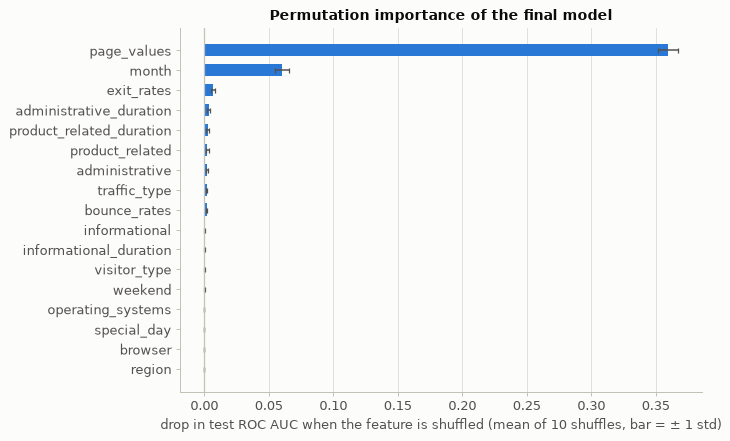

In [39]:
fig, ax = plt.subplots(figsize=(8, 5))
ordered = importance.iloc[::-1]
ax.barh(ordered["feature"], ordered["drop in ROC AUC"], xerr=ordered["std"], color=BLUE, height=0.62, error_kw={"ecolor": INK_SECONDARY, "elinewidth": 1.2, "capsize": 2})
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_xlabel("drop in test ROC AUC when the feature is shuffled (mean of 10 shuffles, bar = ± 1 std)")
ax.set_title("Permutation importance of the final model")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "feature_importance.png", bbox_inches="tight")
plt.show()

How much does the model depend on `page_values`? The same model is cross-validated once more
without that feature:

In [40]:
def drop_page_values(X: np.ndarray, fold_dv: DictVectorizer) -> np.ndarray:
    return np.delete(X, fold_dv.vocabulary_["page_values"], axis=1)


without_page_values = cv_evaluate(lambda: HistGradientBoostingClassifier(early_stopping=False, random_state=SEED, **best_hgb_params), drop_page_values)
pd.DataFrame(
    {
        "CV ROC AUC": {"all features": tuned["Gradient boosting (scikit-learn)"]["auc_mean"], "without page_values": without_page_values["auc_mean"]},
        "CV average precision": {"all features": tuned["Gradient boosting (scikit-learn)"]["ap_mean"], "without page_values": without_page_values["ap_mean"]},
    }
)

,CV ROC AUC,CV average precision
all features,0.9337,0.7474
without page_values,0.7813,0.3680


* `page_values` dominates: shuffling it lowers the test ROC AUC by about 0.36, far more
  than any other feature, and without it the cross-validated ROC AUC falls from 0.934 to
  0.781 (still far better than random). The service is therefore only as good as the
  availability and freshness of this Google Analytics metric.
* `month` is a distant second (about 0.06) and the exit rate third (below 0.01). Shuffling
  any other feature changes the ROC AUC by less than 0.004; `visitor_type`, `weekend`,
  `special_day` and the technical codes (`operating_systems`, `browser`, `region`) make no
  measurable difference.
* Compared with section 5: `page_values`, `month` and the exit rate were on top there too.
  `traffic_type` and the page counts and durations looked informative on their own, but add
  little once the three leading features are in the model. Permutation importance splits
  the credit between correlated features, so a small value does not prove that a feature
  would be useless in another model.

### 9.4 Consistency with `train.py` and an example prediction

`train.py` trains the same pipeline with the same data split. If `model.bin` exists, its
predictions on the test set are compared with those of the model trained in this notebook.

In [41]:
if Path("model.bin").exists():
    with open("model.bin", "rb") as f_in:
        artifact = pickle.load(f_in)
    script_probabilities = artifact["pipeline"].predict_proba(records["test"])[:, 1]
    print(f"largest difference between model.bin and the notebook model on the test set: {np.max(np.abs(script_probabilities - test_probabilities)):.2e}")
    print(f"threshold stored in model.bin: {artifact['threshold']:.2f} | threshold found in this notebook: {threshold:.2f}")
else:
    print("model.bin not found: run `python train.py` to create it")

largest difference between model.bin and the notebook model on the test set: 0.00e+00
threshold stored in model.bin: 0.33 | threshold found in this notebook: 0.33


In [42]:
example = {
    "administrative": 3,
    "administrative_duration": 87.5,
    "informational": 0,
    "informational_duration": 0.0,
    "product_related": 34,
    "product_related_duration": 1280.4,
    "bounce_rates": 0.004,
    "exit_rates": 0.017,
    "page_values": 21.3,
    "special_day": 0.0,
    "month": "Nov",
    "operating_systems": 2,
    "browser": 2,
    "region": 1,
    "traffic_type": 2,
    "visitor_type": "Returning_Visitor",
    "weekend": False,
}
probability = float(final_pipeline.predict_proba([prepare_record(example)])[0, 1])
print(f"purchase probability = {probability:.4f} | flagged as purchase: {probability >= threshold}")

purchase probability = 0.6407 | flagged as purchase: True


## 10. Conclusions and limitations

* The data is clean (no missing values); the only preparation needed is a label fix and
  treating the integer codes as categories.
* Purchases are rare (15.5%), so models are compared with ROC AUC and average precision.
* Five model families were tuned with 5-fold cross-validation. The three tree ensembles are
  statistically tied and clearly better than a single tree or logistic regression. Gradient
  boosting from scikit-learn has the best mean score and the lightest deployment, and is the
  final model.
* On the untouched test set the final model reaches a ROC AUC of about 0.94 and an average
  precision of about 0.78, with well-calibrated probabilities.

**Limitations**

* **One shop, one year, no timestamps.** The split is random, not chronological, so the
  scores describe performance on sessions from the same period, not on future traffic.
  January and April are absent, so the model has never seen those months.
* **Session-level totals.** The features describe a finished session. Scoring a session
  while it is still in progress means using partial counts and durations; how well the model
  works at early stages of a session cannot be measured with this dataset.
* **Dependence on `page_values`.** Most of the predictive power comes from one Google
  Analytics metric that reflects visits to pages close to the transaction.
* **Threshold.** The F1-optimal threshold is a neutral default, not a business optimum; the
  right operating point depends on the cost of an intervention and the value of a sale.

In [43]:
print(f"notebook run time: {time.time() - NOTEBOOK_START:.0f} seconds")

notebook run time: 272 seconds
